In [1]:
import sys
sys.path.append("..")

In [1]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_properties(0).total_memory / 1024**3)

True
NVIDIA A100-SXM4-40GB
39.4935302734375


In [2]:
import h5py
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ddpm.data.das_dataset import DasDataset
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler
from IPython.display import clear_output

**Model 4 : Earthquake Baseline 1001 :**
*standard shuffled loader*
**unet_model_spcii**

In [3]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_earthquake = [das_data/"train_1001.h5"]
test_files_earthquake = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_earthquake = DasDataset(train_files_earthquake)
test_set_earthquake = DasDataset(test_files_earthquake)
train_loader_earthquake = DataLoader(train_set_earthquake, batch_size=16, shuffle=True)
test_loader_earthquake = DataLoader(test_set_earthquake, batch_size=16, shuffle=False)

In [4]:
from ddpm.models.unet_spcii import DDPM
model_earthquake_spcii =  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)

In [5]:
x_E = next(iter(train_loader_earthquake)).to(device)
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)
t = torch.randint(0,scheduler_E.betas.shape[0], (x_E.shape[0],), device= device).long()
with torch.no_grad():
    noise_prediction_E = model_earthquake_spcii(x_E,t)
print("shape of input: ", x_E.shape)
print("shape of output: ", noise_prediction_E.shape)

shape of input:  torch.Size([16, 1, 256, 512])
shape of output:  torch.Size([16, 1, 256, 512])


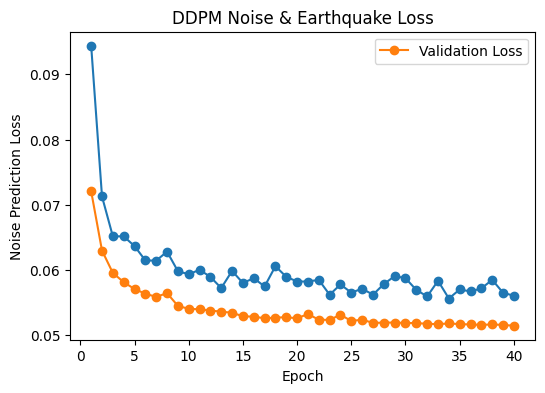

In [6]:
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_earthquake_path=checkpoints/"das_ddpm_earthquake_model_spcii3.pth"
earthquake_loss_plot_path=checkpoints/"das_ddpm_earthquake_loss_spcii3.png"

optimizer_earthquake_spcii= torch.optim.Adam(model_earthquake_spcii.parameters(), lr=1e-4)

epochs_earthquake = 40 
earthquake_train_losses = []
earthquake_val_losses = []
earthquake_start_epoch = 0


if model_earthquake_path.exists():
    checkpoint = torch.load(model_earthquake_path,map_location=device)
    if "model_earthquake_spcii" in checkpoint:
        model_earthquake_spcii.load_state_dict(checkpoint["model_earthquake_spcii"])
    if "optimizer_earthquake_spcii" in checkpoint:
        optimizer_earthquake_spcii.load_state_dict(checkpoint["optimizer_earthquake_spcii"])
    earthquake_train_losses= checkpoint.get("earthquake_train_losses", [])
    earthquake_val_losses= checkpoint.get("earthquake_val_losses", [])
    earthquake_start_epoch=checkpoint.get("completed_epochs", len(earthquake_train_losses)) 

for epoch in range(earthquake_start_epoch, epochs_earthquake):

    model_earthquake_spcii.train()
    epoch_loss= 0.0

    for batch in tqdm(train_loader_earthquake, desc=f"Epoch{epoch+1}/{epochs_earthquake}"):

        x=batch.to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler_E.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler_E.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_earthquake_spcii(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer_earthquake_spcii.zero_grad()
        loss.backward()
        optimizer_earthquake_spcii.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader_earthquake)
    earthquake_train_losses.append(avg_loss)

    model_earthquake_spcii.eval()
    val_epoch_loss = 0.0
    val_seed = torch.Generator(device=device).manual_seed(42)

    with torch.no_grad():
        for batch in test_loader_earthquake:
            x_v = batch.to(device)
            epsilon_v = torch.randn(x_v.shape, device=device, generator=val_seed)
            t_v = torch.randint(0,scheduler_E.betas.shape[0],(x_v.shape[0],),device=device, generator=val_seed).long()
            xt_v=scheduler_E.add_noise(x0=x_v, epsilon=epsilon_v,t=t_v)
            noise_prediction_v = model_earthquake_spcii(xt_v,t_v)
            loss_v = ((noise_prediction_v -epsilon_v)**2).mean()
            val_epoch_loss+= loss_v.item()
    avg_val_loss = val_epoch_loss/len(test_loader_earthquake)
    earthquake_val_losses.append(avg_val_loss)   
   
    torch.save({
    "model_earthquake_spcii": model_earthquake_spcii.state_dict(), "optimizer_earthquake_spcii": optimizer_earthquake_spcii.state_dict(),"earthquake_train_losses":earthquake_train_losses, 
    "earthquake_val_losses": earthquake_val_losses,
                  "completed_epochs": epoch+1, "base_channels": 64, "channels_multipilier": ( 1,1,2,2,4),
                  "normalizartion": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0}
     }, model_earthquake_path)
    
    clear_output(wait =  True)
    plt.figure(figsize = (6,4))
    plt.plot(range(1,len(earthquake_train_losses)+1), earthquake_train_losses, marker="o")
    plt.plot(range(1,len(earthquake_val_losses)+1), earthquake_val_losses, marker="o", label = "Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM Noise & Earthquake Loss")
    plt.legend()
    plt.savefig(earthquake_loss_plot_path)
    plt.show() 


In [7]:
checkpoints=Path("checkpoints")
model_earthquake_path= Path(checkpoints)/"das_ddpm_earthquake_model_spcii3.pth"
checkpoint_earthquake_spcii = torch.load(model_earthquake_path, map_location = device)
model_earthquake_spcii.load_state_dict(checkpoint_earthquake_spcii["model_earthquake_spcii"])
model_earthquake_spcii = model_earthquake_spcii.to(device)

In [8]:
num_images = 2
xt = torch.randn(num_images, 1,256,512, device = device)
print(xt.shape)
timesteps_shown = [999, 600 , 300, 100, 0]

torch.Size([2, 1, 256, 512])


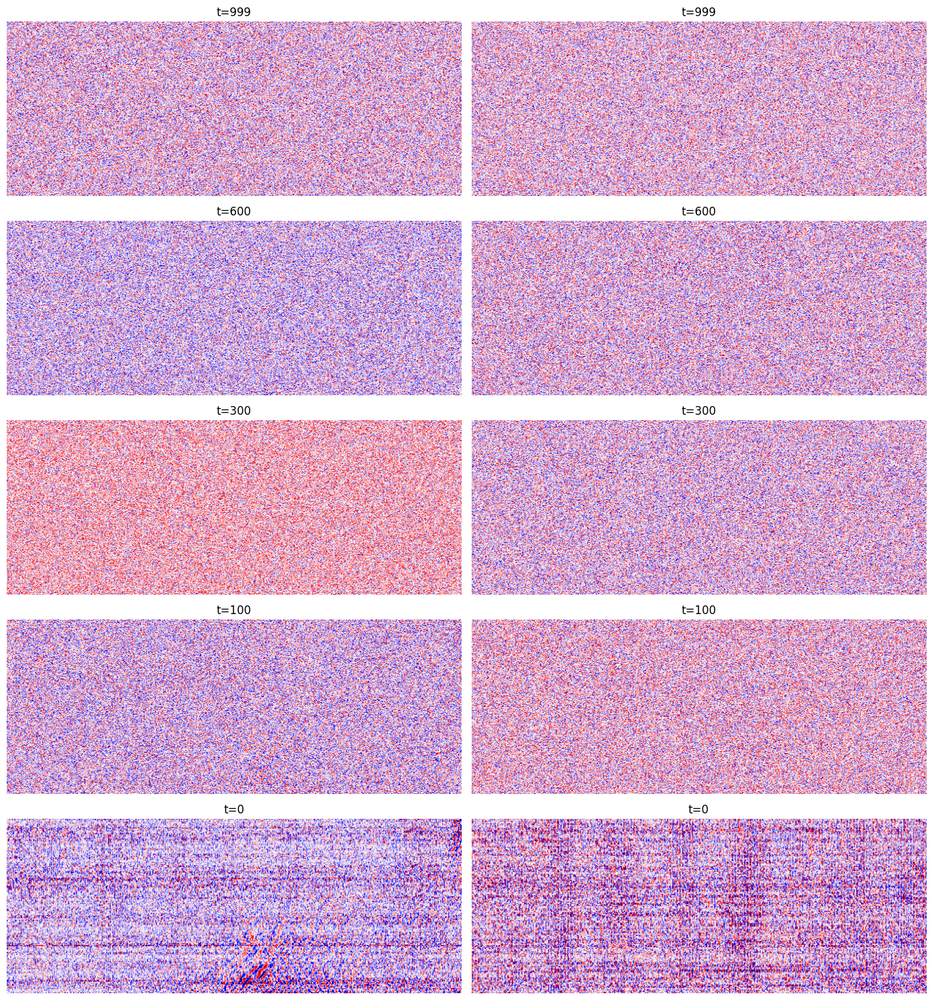

In [9]:
num_rows = len(timesteps_shown)
fig2, axes2 = plt.subplots(num_rows, num_images, figsize = (7*num_images, 3*num_rows))
model_earthquake_spcii.eval()
with torch.no_grad():
    for step in reversed(range(scheduler_E.betas.shape[0])):
        if step in timesteps_shown:
            row= timesteps_shown.index(step)
            for i in range(num_images):
                axes2[row,i].imshow(xt[i,0].detach().cpu(), aspect="auto", cmap="seismic") 
                axes2[row,i].axis("off")
                axes2[row,i].set_title(f"t={step}")
        t=torch.full((num_images,),step, device=device, dtype= torch.long)
        predicted_noise=model_earthquake_spcii(xt,t)
        xt,x0_predicted=scheduler_E.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()

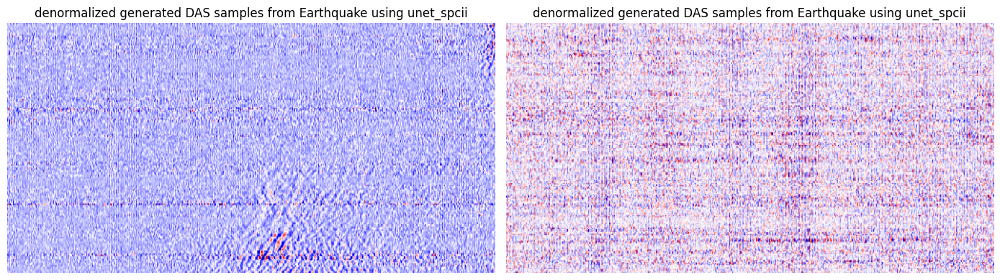

In [10]:
from ddpm.utils.normalizer import denormalize
denormalized = denormalize(xt)
fig3, axes3 = plt.subplots(1, num_images, figsize = (7*num_images,4))
for i in range(num_images):
                axes3[i].imshow(denormalized[i,0].detach().cpu(), aspect="auto", cmap="seismic" ) 
                axes3[i].axis("off")
                axes3[i].set_title("denormalized generated DAS samples from Earthquake using unet_spcii")
plt.tight_layout()
plt.show()    

In [11]:
percentiles=[50,60,99,99.9,99.99]
#normalized
x_test_e = next(iter(test_loader_earthquake))[:num_images].to(device)
#denomalized
x_test_e = denormalize(x_test_e).detach().cpu().numpy()
denormalized_tensor_e = denormalize(xt[:num_images])
denormalized_tensor_e= denormalized_tensor_e[:num_images].detach().cpu().numpy()

x_test_percentiles_e = np.percentile(np.abs(x_test_e).reshape(-1), percentiles)
denormalized_percentiles_e = np.percentile(np.abs(denormalized_tensor_e).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS Earthquakes: {x_test_percentiles_e[i]:.2f} |" f" generated DAS Earthquake {denormalized_percentiles_e[i]:.2f}"
    )

50% | real DAS Earthquakes: 37.51 | generated DAS Earthquake 26.25
60% | real DAS Earthquakes: 48.06 | generated DAS Earthquake 32.91
99% | real DAS Earthquakes: 315.15 | generated DAS Earthquake 119.56
99.9% | real DAS Earthquakes: 778.26 | generated DAS Earthquake 185.86
99.99% | real DAS Earthquakes: 1102.59 | generated DAS Earthquake 278.24


In [12]:
import importlib
import ddpm.diffusion.ddim_sampler
importlib.reload(ddpm.diffusion.ddim_sampler)
from ddpm.diffusion.ddim_sampler import ddim_sample

In [14]:
generated_samples = ddim_sample(model =model_earthquake_spcii, num_samples=8, num_steps =50, device=device, eta=0.0)

In [15]:
from tqdm.auto import tqdm
num_samples = 1024
batch_size = 64

generated_samples = []
prog = tqdm(range(0, num_samples, batch_size), desc="DDIM Samples")
for s in prog:
    current_size = min(batch_size, num_samples-s)
    batch = ddim_sample(model = model_earthquake_spcii, num_samples=current_size, num_steps =50, device=device, eta=0.0)
    generated_samples.append(batch.cpu())
    #print(f"{min(s + batch_size, num_samples)}"f"/{num_samples}")
    prog.set_postfix(generated = min(s + batch_size, num_samples))
generated_samples = torch.cat(generated_samples, dim =0)  
print(generated_samples.shape) 

DDIM Samples:   0%|          | 0/16 [00:00<?, ?it/s]

torch.Size([1024, 1, 256, 512])


In [16]:
num_evl = generated_samples.shape[0]
real_samples = []
for batch in test_loader_earthquake :
    real_samples.append(batch)
    if sum (x.shape[0] for x in real_samples) >= num_evl :
        break
real_samples = torch.cat(real_samples, dim=0)[:num_evl]  

In [17]:
from ddpm.utils.normalizer import denormalize
percentiles=[50,60,99,99.9,99.99]
real_denorm = denormalize(real_samples).detach().cpu().numpy()
generated_denorm= denormalize(generated_samples).detach().cpu().numpy()

real_percentiles = np.percentile(np.abs(real_denorm).reshape(-1), percentiles)
generated_percentiles = np.percentile(np.abs(generated_denorm).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS Earthquakes: {real_percentiles[i]:.2f} |" f" generated DAS Earthquake {generated_percentiles[i]:.2f}"
    )

50% | real DAS Earthquakes: 41.86 | generated DAS Earthquake 25.56
60% | real DAS Earthquakes: 55.94 | generated DAS Earthquake 32.58
99% | real DAS Earthquakes: 1229.64 | generated DAS Earthquake 250.59
99.9% | real DAS Earthquakes: 2891.07 | generated DAS Earthquake 713.09
99.99% | real DAS Earthquakes: 5326.53 | generated DAS Earthquake 1691.90


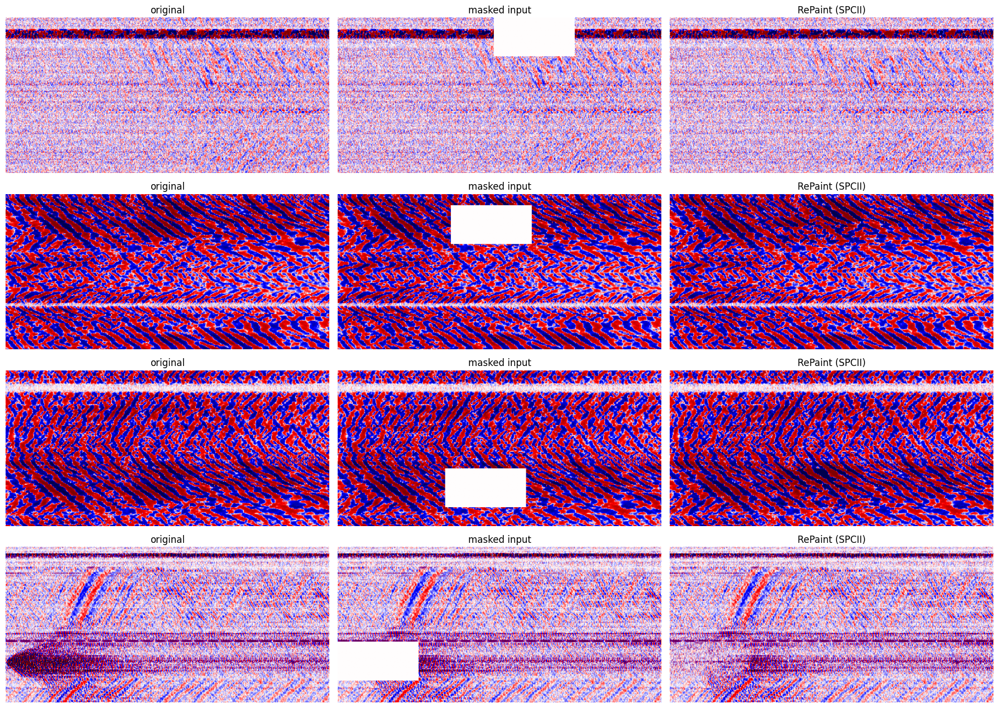

patch 0: RMS ratio inpainted/true = 0.94 | correlation = 0.01
patch 1: RMS ratio inpainted/true = 1.03 | correlation = 0.24
patch 2: RMS ratio inpainted/true = 1.06 | correlation = 0.01
patch 3: RMS ratio inpainted/true = 0.40 | correlation = 0.04


In [ ]:
import torch, numpy as np, matplotlib.pyplot as plt
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler
from ddpm.diffusion.repaint import sample_repaint
from ddpm.utils.normalizer import denormalize

scheduler = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4, beta_end=0.02, device=device)
model = model_earthquake_spcii.eval()          

# pick the 4 test patches with the strongest earthquake energy
patches, scores = [], []
for batch in test_loader_earthquake:
    patches.append(batch)
    scores.append(torch.quantile(denormalize(batch).abs().flatten(1), 0.999, dim=1))
    if sum(p.shape[0] for p in patches) >= 512: break
patches, scores = torch.cat(patches), torch.cat(scores)
x0 = patches[scores.argsort(descending=True)[:4]].to(device)
B, _, H, W = x0.shape

# mask a 64 x 128 block centred on the strongest arrival of each patch
mask = torch.ones_like(x0)
for b in range(B):
    energy = x0[b, 0].abs()
    i, j = divmod(energy.argmax().item(), W)
    i0, j0 = min(max(i - 32, 0), H - 64), min(max(j - 64, 0), W - 128)
    mask[b, :, i0:i0+64, j0:j0+128] = 0.0       # 0 = region to reconstruct

#RePaint
torch.manual_seed(0)
result, _, _ = sample_repaint(model, scheduler, x0, mask, jump_length=10, jump_n_sample=3)

# plot with a shared symmetric colour scale per patch
fig, axes = plt.subplots(B, 3, figsize=(18, 3.2*B))
for b in range(B):
    v = x0[b, 0].abs().quantile(0.99).item()
    for ax, img, title in zip(axes[b],
                              [x0[b, 0], (x0*mask)[b, 0], result[b, 0]],
                              ["original", "masked input", "RePaint (SPCII)"]):
        ax.imshow(img.detach().cpu(), aspect="auto", cmap="seismic", vmin=-v, vmax=v)
        ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

#numbers inside the reconstructed area
hole = (mask == 0)
for b in range(B):
    t, g = x0[b][hole[b]], result[b][hole[b]]
    rms = (g.pow(2).mean().sqrt() / t.pow(2).mean().sqrt()).item()
    corr = torch.corrcoef(torch.stack([t, g]))[0, 1].item()
    print(f"patch {b}: RMS ratio inpainted/true = {rms:.2f} | correlation = {corr:.2f}")